In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import time

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd

url = (
    "https://d37ci6vzurychx.cloudfront.net/"
    "trip-data/yellow_tripdata_2024-01.parquet"
)

df = pd.read_parquet(url)

print("Dataset downloaded successfully!")
print("Rows and columns:", df.shape)

df.head()

Dataset downloaded successfully!
Rows and columns: (2964624, 19)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,2,2024-01-01 00:57:55,2024-01-01 01:17:43,1.0,1.72,1.0,N,186,79,2,17.7,1.0,0.5,0.00,0.0,1.0,22.70,2.5,0.0
1,1,2024-01-01 00:03:00,2024-01-01 00:09:36,1.0,1.80,1.0,N,140,236,1,10.0,3.5,0.5,3.75,0.0,1.0,18.75,2.5,0.0
2,1,2024-01-01 00:17:06,2024-01-01 00:35:01,1.0,4.70,1.0,N,236,79,1,23.3,3.5,0.5,3.00,0.0,1.0,31.30,2.5,0.0
3,1,2024-01-01 00:36:38,2024-01-01 00:44:56,1.0,1.40,1.0,N,79,211,1,10.0,3.5,0.5,2.00,0.0,1.0,17.00,2.5,0.0
4,1,2024-01-01 00:46:51,2024-01-01 00:52:57,1.0,0.80,1.0,N,211,148,1,7.9,3.5,0.5,3.20,0.0,1.0,16.10,2.5,0.0


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Dataset shape: (2964624, 19)

Column names:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee']

Data types:
VendorID                          int32
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag               object
PULocationID                      int32
DOLocationID                      int32
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surc

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
count,2.964624e+06,2964624,2964624,2.824462e+06,2.964624e+06,2.824462e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.964624e+06,2.824462e+06,2.824462e+06
mean,1.754204e+00,2024-01-17 00:46:36.431092,2024-01-17 01:02:13.208130,1.339281e+00,3.652169e+00,2.069359e+00,1.660179e+02,1.651167e+02,1.161271e+00,1.817506e+01,1.451598e+00,4.833823e-01,3.335870e+00,5.270212e-01,9.756319e-01,2.680150e+01,2.256122e+00,1.411611e-01
min,1.000000e+00,2002-12-31 22:59:39,2002-12-31 23:05:41,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,-8.990000e+02,-7.500000e+00,-5.000000e-01,-8.000000e+01,-8.000000e+01,-1.000000e+00,-9.000000e+02,-2.500000e+00,-1.750000e+00
25%,2.000000e+00,2024-01-09 15:59:19.750000,2024-01-09 16:16:23,1.000000e+00,1.000000e+00,1.000000e+00,1.320000e+02,1.140000e+02,1.000000e+00,8.600000e+00,0.000000e+00,5.000000e-01,1.000000e+00,0.000000e+00,1.000000e+00,1.538000e+01,2.500000e+00,0.000000e+00
50%,2.000000e+00,2024-01-17 10:45:37.500000,2024-01-17 11:03:51.500000,1.000000e+00,1.680000e+00,1.000000e+00,1.620000e+02,1.620000e+02,1.000000e+00,1.280000e+01,1.000000e+00,5.000000e-01,2.700000e+00,0.000000e+00,1.000000e+00,2.010000e+01,2.500000e+00,0.000000e+00
75%,2.000000e+00,2024-01-24 18:23:52.250000,2024-01-24 18:40:29,1.000000e+00,3.110000e+00,1.000000e+00,2.340000e+02,2.340000e+02,1.000000e+00,2.050000e+01,2.500000e+00,5.000000e-01,4.120000e+00,0.000000e+00,1.000000e+00,2.856000e+01,2.500000e+00,0.000000e+00
max,6.000000e+00,2024-02-01 00:01:15,2024-02-02 13:56:52,9.000000e+00,3.127223e+05,9.900000e+01,2.650000e+02,2.650000e+02,4.000000e+00,5.000000e+03,1.425000e+01,4.000000e+00,4.280000e+02,1.159200e+02,1.000000e+00,5.000000e+03,2.500000e+00,1.750000e+00
std,4.325902e-01,NaN,NaN,8.502817e-01,2.254626e+02,9.823219e+00,6.362391e+01,6.931535e+01,5.808686e-01,1.894955e+01,1.804102e+00,1.177600e-01,3.896551e+00,2.128310e+00,2.183645e-01,2.338558e+01,8.232747e-01,4.876239e-01


In [4]:
print("Number of records:", len(df))
print("Number of columns:", len(df.columns))

memory_usage = df.memory_usage(deep=True).sum()

print("DataFrame memory usage:", round(memory_usage / (1024**2), 2), "MB")

Number of records: 2964624
Number of columns: 19
DataFrame memory usage: 511.09 MB


In [5]:
print("Original dataset shape:", df.shape)

df = df.drop_duplicates()

df = df[
    (df["trip_distance"] > 0) &
    (df["fare_amount"] >= 0)
].copy()

print("Cleaned dataset shape:", df.shape)

Original dataset shape: (2964624, 19)
Cleaned dataset shape: (2870188, 19)


In [6]:
missing_values = df.isnull().sum()

display(
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
)

,0
passenger_count,115293
RatecodeID,115293
store_and_fwd_flag,115293
congestion_surcharge,115293
Airport_fee,115293


In [7]:
print("Remaining duplicate rows:", df.duplicated().sum())

Remaining duplicate rows: 0


In [8]:
!apt-get update -qq
!apt-get install -y openjdk-11-jdk-headless

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  openjdk-11-jre-headless
Suggested packages:
  openjdk-11-demo openjdk-11-source libnss-mdns fonts-dejavu-extra
  fonts-ipafont-gothic fonts-ipafont-mincho fonts-wqy-microhei
  | fonts-wqy-zenhei fonts-indic
The following NEW packages will be installed:
  openjdk-11-jdk-headless openjdk-11-jre-headless
0 upgraded, 2 newly installed, 0 to remove and 24 not upgraded.
Need to get 116 MB of archives.
After this operation, 258 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 openjdk-11-jre-headless amd64 11.0.32.1+1-1ubuntu1~24.04 [42.3 MB]
Get:2 http://archive.ubuntu.com/ubuntu noble-updates/univ

In [9]:
!java -version

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


In [10]:
!wget -q https://archive.apache.org/dist/hadoop/common/hadoop-3.3.6/hadoop-3.3.6.tar.gz
!tar -xzf hadoop-3.3.6.tar.gz

In [11]:
import os

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-11-openjdk-amd64"
os.environ["HADOOP_HOME"] = "/content/hadoop-3.3.6"
os.environ["PATH"] += ":/content/hadoop-3.3.6/bin:/content/hadoop-3.3.6/sbin"

print("Hadoop environment variables configured.")

Hadoop environment variables configured.


In [12]:
!hadoop version

Hadoop 3.3.6
Source code repository https://github.com/apache/hadoop.git -r 1be78238728da9266a4f88195058f08fd012bf9c
Compiled by ubuntu on 2023-06-18T08:22Z
Compiled on platform linux-x86_64
Compiled with protoc 3.7.1
From source with checksum 5652179ad55f76cb287d9c633bb53bbd
This command was run using /content/hadoop-3.3.6/share/hadoop/common/hadoop-common-3.3.6.jar


In [13]:
%%writefile /content/hadoop-3.3.6/etc/hadoop/core-site.xml
<?xml version="1.0"?>
<configuration>
    <property>
        <name>fs.defaultFS</name>
        <value>hdfs://localhost:9000</value>
    </property>
</configuration>

Overwriting /content/hadoop-3.3.6/etc/hadoop/core-site.xml


In [14]:
%%writefile /content/hadoop-3.3.6/etc/hadoop/hdfs-site.xml
<?xml version="1.0"?>
<configuration>
    <property>
        <name>dfs.replication</name>
        <value>1</value>
    </property>
    <property>
        <name>dfs.namenode.name.dir</name>
        <value>file:///content/hadoop-3.3.6/data/namenode</value>
    </property>
    <property>
        <name>dfs.datanode.data.dir</name>
        <value>file:///content/hadoop-3.3.6/data/datanode</value>
    </property>
</configuration>

Overwriting /content/hadoop-3.3.6/etc/hadoop/hdfs-site.xml


In [15]:
!hdfs namenode -format -force

2026-10-11 13:27:50,194 INFO namenode.NameNode: STARTUP_MSG: 
/************************************************************
STARTUP_MSG: Starting NameNode
STARTUP_MSG:   host = ddf403189a66/172.28.0.12
STARTUP_MSG:   args = [-format, -force]
STARTUP_MSG:   version = 3.3.6
STARTUP_MSG:   classpath = /content/hadoop-3.3.6/etc/hadoop:/content/hadoop-3.3.6/share/hadoop/common/lib/jsp-api-2.1.jar:/content/hadoop-3.3.6/share/hadoop/common/lib/netty-handler-ssl-ocsp-4.1.89.Final.jar:/content/hadoop-3.3.6/share/hadoop/common/lib/guava-27.0-jre.jar:/content/hadoop-3.3.6/share/hadoop/common/lib/jetty-http-9.4.51.v20230217.jar:/content/hadoop-3.3.6/share/hadoop/common/lib/metrics-core-3.2.4.jar:/content/hadoop-3.3.6/share/hadoop/common/lib/jersey-json-1.20.jar:/content/hadoop-3.3.6/share/hadoop/common/lib/jettison-1.5.4.jar:/content/hadoop-3.3.6/share/hadoop/common/lib/re2j-1.1.jar:/content/hadoop-3.3.6/share/hadoop/common/lib/netty-transport-classes-kqueue-4.1.89.Final.jar:/content/hadoop-3.3.6/

In [16]:
!hdfs version

Hadoop 3.3.6
Source code repository https://github.com/apache/hadoop.git -r 1be78238728da9266a4f88195058f08fd012bf9c
Compiled by ubuntu on 2023-06-18T08:22Z
Compiled on platform linux-x86_64
Compiled with protoc 3.7.1
From source with checksum 5652179ad55f76cb287d9c633bb53bbd
This command was run using /content/hadoop-3.3.6/share/hadoop/common/hadoop-common-3.3.6.jar


In [17]:
df.to_csv(
    "/content/taxi_cleaned.csv",
    index=False
)

print("Cleaned dataset saved.")

Cleaned dataset saved.


In [18]:
!hdfs dfs -mkdir -p /taxi_data

mkdir: Call From ddf403189a66/172.28.0.12 to localhost:9000 failed on connection exception: java.net.ConnectException: Connection refused; For more details see:  http://wiki.apache.org/hadoop/ConnectionRefused


In [19]:
!hdfs dfs -put -f /content/taxi_cleaned.csv /taxi_data/

put: Call From ddf403189a66/172.28.0.12 to localhost:9000 failed on connection exception: java.net.ConnectException: Connection refused; For more details see:  http://wiki.apache.org/hadoop/ConnectionRefused


In [20]:
!hdfs dfs -ls /taxi_data

ls: Call From ddf403189a66/172.28.0.12 to localhost:9000 failed on connection exception: java.net.ConnectException: Connection refused; For more details see:  http://wiki.apache.org/hadoop/ConnectionRefused


In [21]:
%%writefile mapper.py
#!/usr/bin/env python3

import sys
import csv

reader = csv.DictReader(sys.stdin)

for row in reader:
    try:
        pickup = row["tpep_pickup_datetime"]
        fare = float(row["total_amount"])

        date = pickup[:10]

        if date:
            print(f"{date}\t{fare}")

    except (ValueError, KeyError, TypeError):
        continue

Writing mapper.py


In [22]:
%%writefile reducer.py
#!/usr/bin/env python3

import sys

current_date = None
total = 0.0

for line in sys.stdin:
    line = line.strip()

    try:
        date, amount = line.split("\t", 1)
        amount = float(amount)
    except ValueError:
        continue

    if current_date == date:
        total += amount
    else:
        if current_date is not None:
            print(f"{current_date}\t{total:.2f}")

        current_date = date
        total = amount

if current_date is not None:
    print(f"{current_date}\t{total:.2f}")

Writing reducer.py


In [23]:
sample = df[
    ["tpep_pickup_datetime", "total_amount"]
].head(1000)

sample.to_csv(
    "/content/sample_taxi.csv",
    index=False
)

print("Sample created.")

Sample created.


In [24]:
!python mapper.py < /content/sample_taxi.csv > /content/mapper_output.txt

In [25]:
!head /content/mapper_output.txt

2024-01-01	22.7
2024-01-01	18.75
2024-01-01	31.3
2024-01-01	17.0
2024-01-01	16.1
2024-01-01	41.5
2024-01-01	64.95
2024-01-01	30.4
2024-01-01	36.0
2024-01-01	8.0


In [26]:
!sort /content/mapper_output.txt | python reducer.py

2023-12-31	43.90
2024-01-01	26928.01


In [27]:
total_revenue = df["total_amount"].sum()

print("Total Revenue:", round(total_revenue, 2))

Total Revenue: 78483361.61


In [28]:
total_trips = len(df)

print("Total Trips:", total_trips)

Total Trips: 2870188


In [29]:
average_fare = df["fare_amount"].mean()

print("Average Fare:", round(average_fare, 2))

Average Fare: 18.5


In [30]:
average_distance = df["trip_distance"].mean()

print("Average Trip Distance:", round(average_distance, 2))

Average Trip Distance: 3.73


In [31]:
payment_analysis = (
    df.groupby("payment_type")
      .agg(
          total_trips=("payment_type", "size"),
          total_revenue=("total_amount", "sum")
      )
      .reset_index()
)

display(payment_analysis)

,payment_type,total_trips,total_revenue
0,0,115293,3056887.60
1,1,2298422,64529522.25
2,2,422945,10089325.01
3,3,10649,235562.14
4,4,22879,572064.61


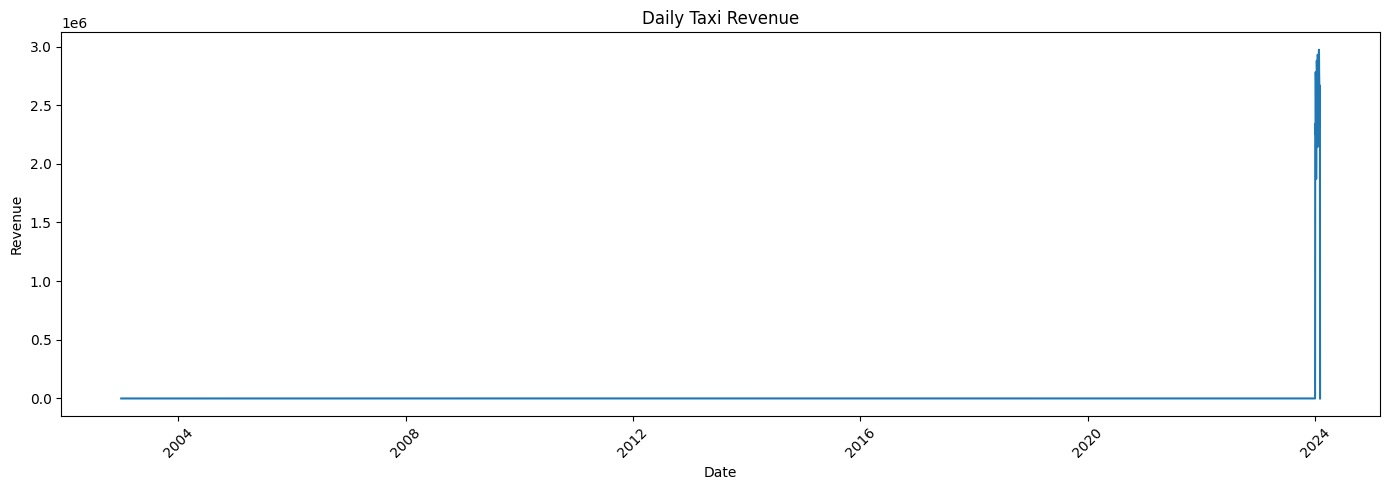

In [32]:
df["pickup_date"] = pd.to_datetime(
    df["tpep_pickup_datetime"],
    errors="coerce"
).dt.date

daily_revenue = (
    df.groupby("pickup_date")["total_amount"]
      .sum()
      .reset_index()
)

plt.figure(figsize=(14, 5))

plt.plot(
    daily_revenue["pickup_date"],
    daily_revenue["total_amount"]
)

plt.title("Daily Taxi Revenue")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

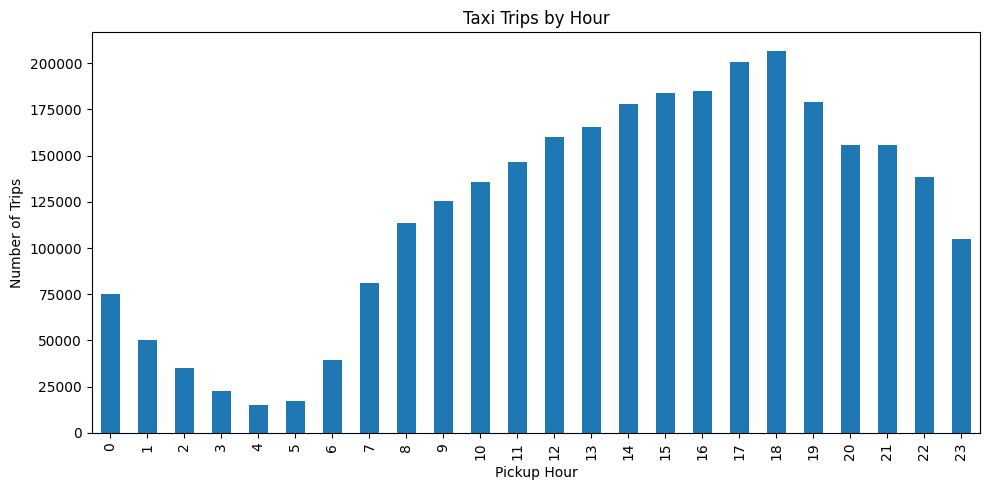

In [33]:
df["pickup_hour"] = pd.to_datetime(
    df["tpep_pickup_datetime"],
    errors="coerce"
).dt.hour

hourly_trips = df.groupby("pickup_hour").size()

plt.figure(figsize=(10, 5))

hourly_trips.plot(kind="bar")

plt.title("Taxi Trips by Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

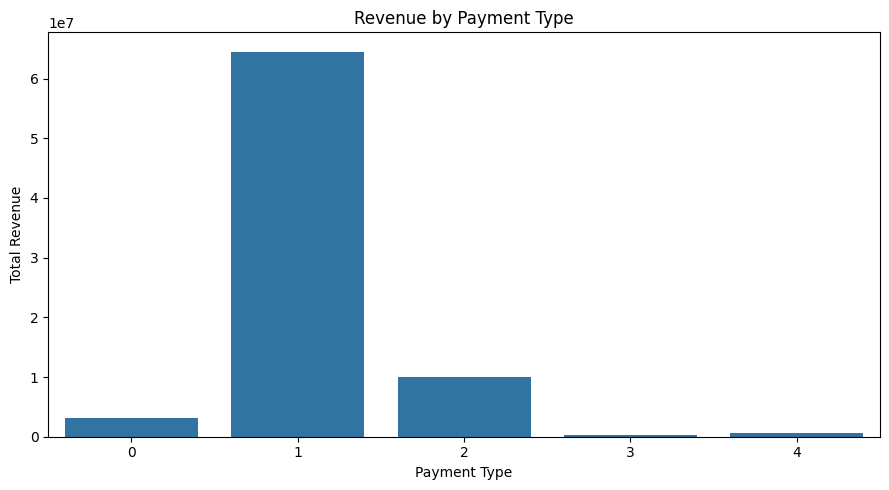

In [34]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=payment_analysis,
    x="payment_type",
    y="total_revenue"
)

plt.title("Revenue by Payment Type")
plt.xlabel("Payment Type")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

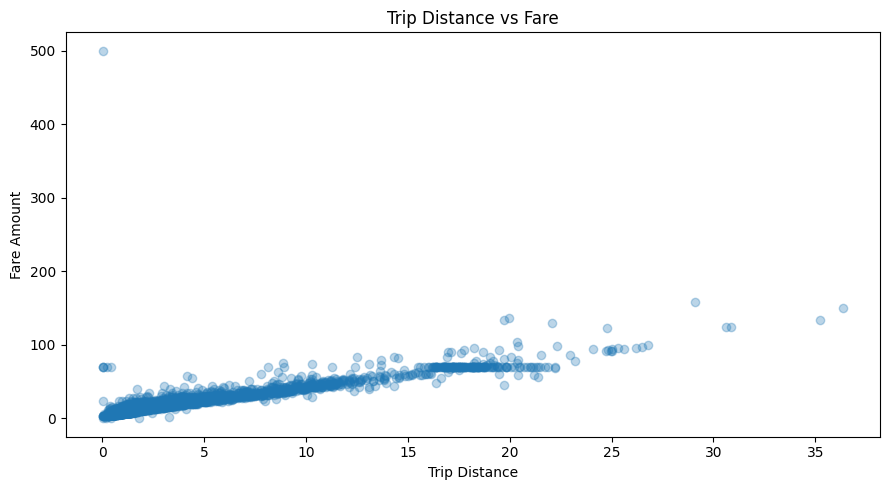

In [35]:
sample = df.sample(
    min(5000, len(df)),
    random_state=42
)

plt.figure(figsize=(9, 5))

plt.scatter(
    sample["trip_distance"],
    sample["fare_amount"],
    alpha=0.3
)

plt.title("Trip Distance vs Fare")
plt.xlabel("Trip Distance")
plt.ylabel("Fare Amount")
plt.tight_layout()
plt.show()

In [36]:
import os

os.makedirs("/content/project_output", exist_ok=True)

In [37]:
df.to_csv(
    "/content/project_output/taxi_cleaned.csv",
    index=False
)

In [38]:
daily_revenue.to_csv(
    "/content/project_output/daily_revenue.csv",
    index=False
)

payment_analysis.to_csv(
    "/content/project_output/payment_analysis.csv",
    index=False
)

hourly_trips.rename(
    "total_trips"
).to_csv(
    "/content/project_output/hourly_trips.csv"
)

In [39]:
!ls -lh /content/project_output

total 325M
-rw-r--r-- 1 root root  774 Oct 11 13:33 daily_revenue.csv
-rw-r--r-- 1 root root  246 Oct 11 13:33 hourly_trips.csv
-rw-r--r-- 1 root root  137 Oct 11 13:33 payment_analysis.csv
-rw-r--r-- 1 root root 325M Oct 11 13:33 taxi_cleaned.csv
